# Phase 3 — Pit Stop Strategy

**The question:** how many times should you stop, and when?

Unlike Phases 1 and 2 this involves **no model training**. It consumes Phase 2's degradation
rates and turns them into a decision. That shift — from prediction to decision — brings its own
set of ideas, and they are the real content here.

**What you'll learn:**
1. The whole trade-off in one line of algebra, and three things it tells you for free
2. Why a closed form and a lap-by-lap loop are both worth writing
3. The filter lesson, for the third time — now in pit-loss data
4. **Common random numbers**: why comparing on shared scenarios cuts the noise 15×
5. Why the safety car matters through exactly *one* channel
6. Expected value vs variance — when the slower strategy is the right call

In [1]:
import warnings, logging
warnings.filterwarnings('ignore')
logging.getLogger('fastf1').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from app.db.base import engine
from app.ml.tire import dataset as ds
from app.ml.strategy import inputs as si, simulator as sim, monte_carlo as mc
from app.ml.strategy import enumerate_strategies as en

pd.set_option('display.width', 200)
laps = ds.build_dataset(engine)
print(f'{len(laps):,} clean race laps across {sorted(laps.season_year.unique())}')

103,975 clean race laps across [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


## 1. The whole problem, in one line

Total race time is every lap plus every stop. A lap on a tire `age` laps old at race lap `n`:

```
lap_time = base_pace + degradation x (age-1) + fuel_penalty(n)
```

Sum that over a stint of length L. The degradation term is an **arithmetic series**:

```
sum over age=1..L of slope*(age-1)  =  slope * L*(L-1)/2
```

So the only strategy-dependent part of a race time is:

```
cost(strategy) = SUM over stints of  slope(compound) * L*(L-1)/2   +   stops * pit_loss
```

Base pace and fuel are identical for every strategy at a given race distance, so they cancel.

**Three things follow immediately, without running anything:**

| # | Consequence | Why |
|---|---|---|
| 1 | Stint **order** does not affect the deterministic cost | the formula has no ordering term |
| 2 | Long stints are punished **quadratically** | `L*(L-1)/2` is convex, so even splits win |
| 3 | An extra stop costs a **fixed** `pit_loss` and buys a **quadratic** degradation saving | that trade is the entire game |

Consequence 3 is why abrasive circuits want more stops than smooth ones. Let's make it exact.

In [2]:
# Derive the threshold where a second stop starts paying, for a 50-lap race.
# 1-stop splits 25/25:      slope * 2 * (25*24/2) = slope * 600
# 2-stop splits 17/17/16:   slope * (136+136+120) = slope * 392
# So a second stop SAVES slope*208 and COSTS one pit_loss.
pit_loss_s = 22.0
threshold = pit_loss_s / 208
print(f'a second stop pays when degradation > {threshold:.4f} s/lap')
print()
print('Phase 2 measured, per circuit:')
from app.ml.tire import stage_a
fits = stage_a.fit_all_stints(laps, use_fuel_correction=True)
table = stage_a.degradation_lookup(fits, min_stints=10)
by_circuit = table.groupby('circuit').slope_median.median().sort_values()
print(f'  lowest : {by_circuit.index[0]:<18}{by_circuit.iloc[0]:.4f} s/lap')
print(f'  highest: {by_circuit.index[-1]:<18}{by_circuit.iloc[-1]:.4f} s/lap')
print(f'  circuits above the 1-stop/2-stop threshold: '
      f'{(by_circuit > threshold).sum()} of {len(by_circuit)}')

a second stop pays when degradation > 0.1058 s/lap

Phase 2 measured, per circuit:


  lowest : Hockenheim        -0.0481 s/lap
  highest: Sakhir            0.1018 s/lap
  circuits above the 1-stop/2-stop threshold: 0 of 30


In [3]:
# Verify the derivation by brute force, on a single-compound problem.
def uniform(slope, pit_s=22.0, race_laps=50):
    return si.StrategyInputs(circuit='Uniform', race_laps=race_laps, base_pace_ms=90_000.0,
        pit_loss_ms=pit_s*1000, pit_loss_sd_ms=1000.0,
        degradation_s_per_lap={c: slope for c in ('SOFT','MEDIUM','HARD')},
        max_stint_laps={c: 30 for c in ('SOFT','MEDIUM','HARD')},
        sc_probability=0.0, median_sc_laps=0)

print(f'{'slope':>8}{'best':>8}{'1-stop':>12}{'2-stop':>12}{'3-stop':>12}')
for slope in (0.02, 0.08, threshold*0.95, threshold*1.05, 0.20, 0.40):
    best = sim.rank_by_stop_count(uniform(slope), max_stops=3)
    winner = min(best, key=lambda n: best[n].total_ms)
    ref = best[winner].total_ms
    cells = ''.join(f'{(best[n].total_ms-ref)/1000:>+11.1f}s' for n in sorted(best))
    flag = '  <-- threshold' if abs(slope-threshold)/threshold < 0.1 else ''
    print(f'{slope:>8.4f}{winner:>8}{cells}{flag}')
print()
print(f'The flip happens exactly at the derived {threshold:.4f} s/lap. Brute force agrees with algebra.')

   slope    best      1-stop      2-stop      3-stop


  0.0200       1       +0.0s      +17.8s      +37.8s


  0.0800       1       +0.0s       +5.4s      +19.0s


  0.1005       1       +0.0s       +1.1s      +12.7s  <-- threshold


  0.1111       2       +1.1s       +0.0s      +10.4s  <-- threshold


  0.2000       2      +19.6s       +0.0s       +1.2s


  0.4000       3      +80.8s      +19.6s       +0.0s

The flip happens exactly at the derived 0.1058 s/lap. Brute force agrees with algebra.


## 2. Two implementations, on purpose

`deterministic_cost` uses the closed form — O(stints), which is what makes exhaustively ranking
**2.4 million** Monaco strategies practical.

`simulate_lap_by_lap` walks every lap. It is slower and it is the *specification*: it can be
given a safety car, per-lap noise, or traffic.

Writing both is not redundancy. Each checks the other, and that is the strongest test available
short of real-world validation.

In [4]:
i = si.build_inputs(engine, 'Monza', laps=laps)
s = en.build_strategy(('MEDIUM','HARD'), (15, 38))
a, b = sim.simulate(s, i), sim.simulate_lap_by_lap(s, i)
print(f'closed form : {a.total_ms:.6f} ms')
print(f'lap-by-lap  : {b.total_ms:.6f} ms')
print(f'difference  : {abs(a.total_ms-b.total_ms):.2e} ms  <- floating point only')

closed form : 4587489.655675 ms
lap-by-lap  : 4587489.655675 ms
difference  : 2.79e-09 ms  <- floating point only


## 3. The filter lesson, for the third time

Phase 1: `is_accurate` plus a green-flag filter still admitted a 148-second restart lap.
Phase 2: dry compounds still admitted 20-second laps from a drying track.
Phase 3: pit-loss data has the same shape of problem.

First, the **definition** matters. `raw.pit_stops.duration_ms_est` is the time from the pit entry
line to the pit exit line — but that is not what a stop costs you, because it omits the braking
before and the acceleration after. What a strategist needs is:

```
pit_loss = (in_lap + out_lap) - 2 x the driver's normal green-flag pace
```

In [5]:
comparison = pd.read_sql(text('''
    WITH pace AS (
      SELECT session_id, driver_id,
             percentile_cont(0.5) WITHIN GROUP (ORDER BY lap_time_ms) AS normal_ms
      FROM raw.laps l JOIN raw.sessions s ON s.id=l.session_id AND s.session_type='R'
      WHERE l.is_accurate AND l.track_status=ARRAY[1]::smallint[]
        AND l.lap_time_ms IS NOT NULL AND l.pit_in_ms IS NULL AND l.pit_out_ms IS NULL
      GROUP BY 1,2 HAVING count(*)>=10),
    stops AS (
      SELECT (il.lap_time_ms + ol.lap_time_ms - 2*p.normal_ms) AS loss_ms,
             (il.track_status=ARRAY[1]::smallint[] AND ol.track_status=ARRAY[1]::smallint[]) AS both_green
      FROM raw.laps il
      JOIN raw.laps ol ON ol.session_id=il.session_id AND ol.driver_id=il.driver_id
                       AND ol.lap_number=il.lap_number+1 AND ol.pit_out_ms IS NOT NULL
      JOIN pace p ON p.session_id=il.session_id AND p.driver_id=il.driver_id
      WHERE il.pit_in_ms IS NOT NULL AND il.lap_time_ms IS NOT NULL AND ol.lap_time_ms IS NOT NULL)
    SELECT both_green, count(*) AS n,
           round((percentile_cont(0.5) WITHIN GROUP (ORDER BY loss_ms)/1000)::numeric,1) AS median_s,
           round((percentile_cont(0.9) WITHIN GROUP (ORDER BY loss_ms)/1000)::numeric,1) AS p90_s
    FROM stops GROUP BY 1 ORDER BY 1
'''), engine)
print(comparison.to_string(index=False))
print()
print('Including safety-car stops barely moves the MEDIAN (24.6 vs 23.3) but sends')
print('p90 from 32s to 72s. A stop under the safety car has a slow in-lap BY')
print('DEFINITION, so the subtraction blames the safety car on the pit stop.')
print()
print('Looking only at the median would have hidden this completely.')

 both_green    n  median_s  p90_s
      False  943      62.1  104.0
       True 2715      23.3   32.0

Including safety-car stops barely moves the MEDIAN (24.6 vs 23.3) but sends
p90 from 32s to 72s. A stop under the safety car has a slow in-lap BY
DEFINITION, so the subtraction blames the safety car on the pit stop.

Looking only at the median would have hidden this completely.


### The same lesson a third time, stated once

Every filter encodes an assumption about how a session behaves. Three phases in, the pattern is
clear: **the assumption that fails is never the one you were thinking about.** `is_accurate`
doesn't know about standing restarts; a dry-compound filter doesn't know about rain arriving; a
pit-loss formula doesn't know about safety cars.

What caught all three was the same habit: look at the **distribution**, not the summary. The
median was well-behaved in all three cases.

In [6]:
# The measured inputs that drive every recommendation.
rows=[]
for c in si.available_circuits(engine):
    try: inp = si.build_inputs(engine, c, laps=laps)
    except LookupError: continue
    rows.append({'circuit':c,'laps':inp.race_laps,'pit_loss_s':inp.pit_loss_ms/1000,
                 'deg_mean':np.mean(list(inp.degradation_s_per_lap.values())),
                 'p_sc':inp.sc_probability,'n_stops':inp.n_stops_observed})
summary = pd.DataFrame(rows).sort_values('deg_mean', ascending=False)
print(summary.head(10).round(3).to_string(index=False))

          circuit  laps  pit_loss_s  deg_mean  p_sc  n_stops
           Sakhir    57      24.494     0.112 0.857      229
         Shanghai    56      24.437     0.103 1.000       57
           Suzuka    53      23.020     0.093 0.333       90
Spa-Francorchamps    44      19.146     0.088 0.500      130
         Budapest    70      22.045     0.066 0.333      177
           Austin    56      21.543     0.064 0.500      125
        Barcelona    66      23.188     0.061 0.333      226
        São Paulo    71      21.928     0.060 1.000       92
        Las Vegas    50      24.012     0.056 0.500       53
       Yas Island    58      22.956     0.055 0.600      110


## 4. Deterministic ranking, checked against reality

The strongest test available: does the simulator reproduce strategies that actually happened?

In [7]:
print(f'{'circuit':<12}{'laps':>5}{'pit':>7}{'deg':>8}  best strategy')
print('-'*78)
for c in ('Monza','Sakhir','Monaco','Marina Bay','Spa-Francorchamps'):
    inp = si.build_inputs(engine, c, laps=laps)
    best = sim.rank_by_stop_count(inp, max_stops=3)
    winner = min(best, key=lambda n: best[n].total_ms)
    deg = np.mean(list(inp.degradation_s_per_lap.values()))
    print(f'{c:<12}{inp.race_laps:>5}{inp.pit_loss_ms/1000:>6.1f}s{deg:>8.3f}  '
          f'{best[winner].strategy.describe()}')
print()
print('Monza 1-stop  : exactly how Leclerc won there in 2024, and the story of that race.')
print('Sakhir 2-stop : Bahrain is the most abrasive surface on the calendar.')
print('Monaco 1-stop : low-energy circuit, tires barely degrade, a stop buys nothing.')

circuit      laps    pit     deg  best strategy
------------------------------------------------------------------------------


Monza          53  25.9s   0.052  1-stop: SOFT x28 -> HARD x25


Sakhir         57  24.5s   0.112  2-stop: MEDIUM x18 -> HARD x19 -> HARD x20


Monaco         78  22.4s   0.010  1-stop: SOFT x33 -> MEDIUM x45


Marina Bay     62  29.0s   0.028  1-stop: SOFT x28 -> MEDIUM x34


Spa-Francorchamps   44  19.1s   0.088  1-stop: SOFT x21 -> HARD x23

Monza 1-stop  : exactly how Leclerc won there in 2024, and the story of that race.
Sakhir 2-stop : Bahrain is the most abrasive surface on the calendar.
Monaco 1-stop : low-energy circuit, tires barely degrade, a stop buys nothing.


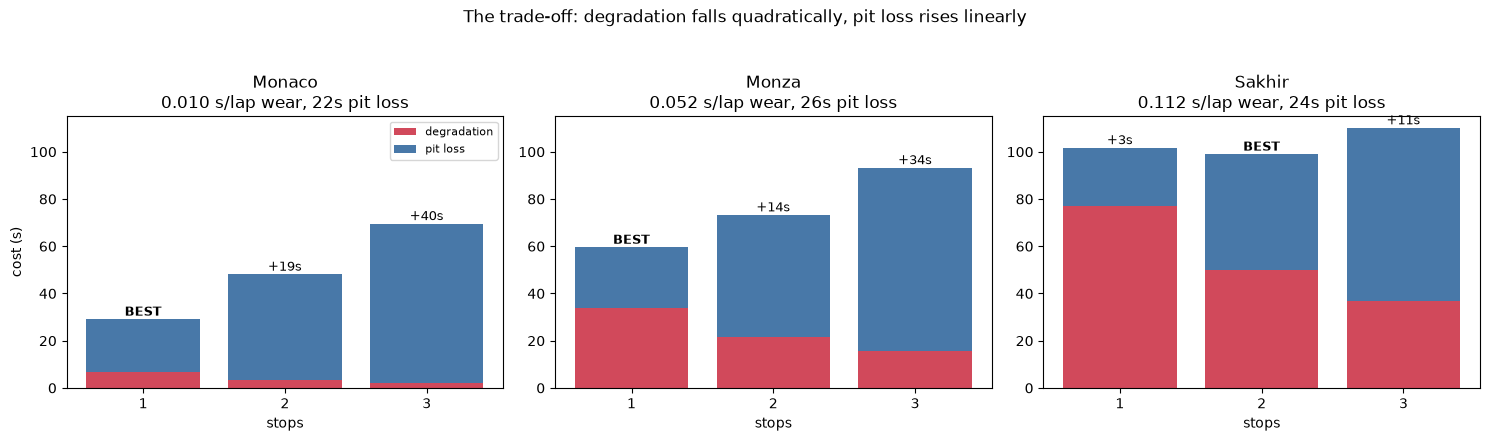

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c in zip(axes, ['Monaco','Monza','Sakhir']):
    inp = si.build_inputs(engine, c, laps=laps)
    best = sim.rank_by_stop_count(inp, max_stops=3)
    ref = min(r.total_ms for r in best.values())
    stops = sorted(best)
    deltas = [(best[n].total_ms-ref)/1000 for n in stops]
    deg_cost = [best[n].degradation_ms/1000 for n in stops]
    pit_cost = [best[n].pit_ms/1000 for n in stops]
    ax.bar([str(n) for n in stops], deg_cost, label='degradation', color='#d1495b')
    ax.bar([str(n) for n in stops], pit_cost, bottom=deg_cost, label='pit loss', color='#4878a8')
    for x,(d,dc,pc) in enumerate(zip(deltas, deg_cost, pit_cost)):
        ax.text(x, dc+pc+1.5, f'+{d:.0f}s' if d else 'BEST', ha='center', fontsize=9,
                fontweight='bold' if not d else 'normal')
    deg = np.mean(list(inp.degradation_s_per_lap.values()))
    ax.set_title(f'{c}\n{deg:.3f} s/lap wear, {inp.pit_loss_ms/1000:.0f}s pit loss')
    ax.set_xlabel('stops'); ax.set_ylim(0, 115)
axes[0].set_ylabel('cost (s)'); axes[0].legend(fontsize=8)
plt.suptitle('The trade-off: degradation falls quadratically, pit loss rises linearly', y=1.04)
plt.tight_layout(); plt.show()

The red bars shrink and the blue bars grow. Where they cross is the optimal stop count, and the
crossing point moves with the circuit — exactly what the algebra said it would do.

At Monaco the red bar is almost invisible: there is nothing for a stop to buy.

## 5. Monte Carlo — and the technique that makes it work

Real races do not go to plan. Three things are random: pit loss (crews fumble), lap times
(traffic, mistakes), and **safety cars** — which 68.6% of races in this data have.

### Common random numbers

Scenarios are drawn **once** and every strategy is evaluated against the **same** ones.

This matters far more than it sounds, and the next cell shows why.

In [9]:
inp = si.build_inputs(engine, 'Sakhir', laps=laps)
strats = [r.strategy for r in sim.rank_by_stop_count(inp, max_stops=3).values()]
dists, wins = mc.compare_strategies(strats, inp, n_scenarios=4000)
ref = min(dists, key=lambda d: d.median_ms)

print(f'Sakhir, {len(strats)} strategies x 4000 SHARED scenarios\n')
print(f"  sd of ONE strategy's race time : {ref.sd_ms/1000:>7.1f}s")
print('  ^ almost entirely the safety-car penalty, which EVERY strategy pays identically')
print()
for d in dists:
    if d is ref: continue
    pd_ = mc.paired_delta(d, ref)
    print(f'  {d.strategy.n_stops}-stop vs best: margin {pd_.median_delta_ms/1000:+7.2f}s  '
          f'sd of margin {pd_.sd_delta_ms/1000:5.2f}s  wins {pd_.win_rate:>4.0%}')
print()
print(f'The MARGIN has an sd of ~9s, not {ref.sd_ms/1000:.0f}s. Same runs, 15x less noise.')
print('That is common random numbers: everything the strategies share cancels when')
print('you subtract them scenario by scenario.')

Sakhir, 3 strategies x 4000 SHARED scenarios

  sd of ONE strategy's race time :   131.1s
  ^ almost entirely the safety-car penalty, which EVERY strategy pays identically

  1-stop vs best: margin   -3.35s  sd of margin  8.68s  wins  22%
  3-stop vs best: margin  -10.66s  sd of margin  9.23s  wins  22%

The MARGIN has an sd of ~9s, not 131s. Same runs, 15x less noise.
That is common random numbers: everything the strategies share cancels when
you subtract them scenario by scenario.


**Why this is not a trick.** We never cared about a strategy's absolute race time — we care
about the *difference* between two strategies. If each got its own random draws, that difference
would carry the variance of both, and separating a genuine 2-second edge from noise would need
vastly more samples.

Report `sd` of a single strategy and the strategies look indistinguishable. Report the sd of the
**margin** and one wins 78% of the time. Same data, opposite conclusion.

## 6. The safety car matters through exactly one channel

This is worth being precise about, because it is easy to over-model.

When a safety car is deployed on lap *k* for *d* laps, **every car on track** runs those laps
slowly. So every strategy pays the same penalty, and it **cancels out of any comparison**.

The safety car changes the ranking through one channel only: a stop made inside the window costs
far less, because the field is already slow. That is the "free pit stop".

In [10]:
# Isolate it: ONE strategy, TWO scenarios differing only in WHERE the SC falls.
strategy = en.build_strategy(('MEDIUM','HARD'), (20, inp.race_laps-20))
print(f'strategy {strategy.label()}, stops on lap {strategy.stop_laps[0]}\n')
covers = mc.Scenario(sc_lap=18, sc_duration=5, pit_multipliers=np.ones(4),
                     lap_noise_ms=np.zeros(inp.race_laps))
misses = mc.Scenario(sc_lap=45, sc_duration=5, pit_multipliers=np.ones(4),
                     lap_noise_ms=np.zeros(inp.race_laps))
lucky,_  = mc.simulate_scenario(strategy, inp, covers)
unlucky,_= mc.simulate_scenario(strategy, inp, misses)
print(f'  SC on laps 18-22 (covers the stop): {lucky/1000:.2f}s')
print(f'  SC on laps 45-49 (misses it)      : {unlucky/1000:.2f}s')
print(f'  saving                            : {(unlucky-lucky)/1000:.2f}s')
print(f'  = pit_loss x (1 - {mc.SC_PIT_LOSS_FACTOR}) = {inp.pit_loss_ms*(1-mc.SC_PIT_LOSS_FACTOR)/1000:.2f}s')
print()
print('Both scenarios have a 5-lap safety car, so the lap-time penalty is identical')
print('and cancels. The entire difference is the discounted pit stop.')

strategy M20 / H37, stops on lap 20

  SC on laps 18-22 (covers the stop): 5811.25s
  SC on laps 45-49 (misses it)      : 5824.73s
  saving                            : 13.47s
  = pit_loss x (1 - 0.45) = 13.47s

Both scenarios have a 5-lap safety car, so the lap-time penalty is identical
and cancels. The entire difference is the discounted pit stop.


In [11]:
# More stops = more lottery tickets.
print(f'{'strategy':<14}{'SC luck rate':>14}{'determ gap':>13}{'MC gap':>10}{'recovered':>12}')
ref_det = min(sim.rank_by_stop_count(inp, max_stops=3)[n].total_ms for n in (1,2,3))
best_by = sim.rank_by_stop_count(inp, max_stops=3)
for d in sorted(dists, key=lambda x: x.strategy.n_stops):
    n = d.strategy.n_stops
    det_gap = (best_by[n].total_ms - ref_det)/1000
    mc_gap  = (d.median_ms - ref.median_ms)/1000
    print(f'  {n}-stop{'':<7}{d.sc_luck_rate:>13.0%}{det_gap:>+12.1f}s{mc_gap:>+9.1f}s{det_gap-mc_gap:>+11.2f}s')
print()
print('Each extra stop is another chance to land under a safety car, so the')
print('Monte Carlo gap is consistently SMALLER than the deterministic gap.')
print('The safety-car lottery partly pays for the extra stop.')

strategy        SC luck rate   determ gap    MC gap   recovered


  1-stop                 14%        +2.7s     +3.3s      -0.64s
  2-stop                 26%        +0.0s     +0.0s      +0.00s
  3-stop                 35%       +11.1s    +10.8s      +0.35s

Each extra stop is another chance to land under a safety car, so the
Monte Carlo gap is consistently SMALLER than the deterministic gap.
The safety-car lottery partly pays for the extra stop.


## 7. Expected value is not the whole decision

Everything so far ranks by median race time. That is the right answer to "which strategy is
fastest on average" — and that is **not always the question**.

Suppose you are 15 seconds behind and need to make it up. A strategy that is slower on average
but has a fatter upside tail may be the correct call, because second place pays the same whether
you lose by 2 seconds or 20.

This is a decision-theory point, not a simulation one, and the Monte Carlo output answers it
directly.

In [12]:
print('P(strategy gains at least X seconds on the median-best strategy)\n')
print(f'{"strategy":<12}' + ''.join(f'{f"+{g}s":>10}' for g in (0,5,10,15,20)))
print('-'*62)
for d in sorted(dists, key=lambda x: x.strategy.n_stops):
    n = d.strategy.n_stops
    if d is ref:
        # The reference is its own baseline, so its row is zero by construction.
        print(f'  {n}-stop{"":<5}' + '  reference (best median)'.ljust(50))
        continue
    gains = ref.total_ms - d.total_ms   # positive => d is faster in that scenario
    cells = ''.join(f'{(gains > g*1000).mean():>9.1%} ' for g in (0,5,10,15,20))
    print(f'  {n}-stop{"":<5}{cells}')
print()
best_n = ref.strategy.n_stops
print(f'The {best_n}-stop has the best median -- it wins most scenarios outright.')
print()
print('Now suppose you are 15s behind and second place pays the same whether you')
print('lose by 2s or 20s. Read down the +15s column: the strategy with the best')
print('median may have essentially NO chance of making up 15s, while a slower one')
print('retains a real chance, because its upside depends on a safety car falling')
print('its way.')
print()
print('Being behind changes the objective from "minimise expected time" to')
print('"maximise P(gain > deficit)". Same simulation, different question,')
print('different answer.')

P(strategy gains at least X seconds on the median-best strategy)

strategy           +0s       +5s      +10s      +15s      +20s
--------------------------------------------------------------
  1-stop         21.8%     13.2%      8.1%      1.1%      0.0% 
  2-stop       reference (best median)                         
  3-stop         21.9%      3.8%      0.1%      0.0%      0.0% 

The 2-stop has the best median -- it wins most scenarios outright.

Now suppose you are 15s behind and second place pays the same whether you
lose by 2s or 20s. Read down the +15s column: the strategy with the best
median may have essentially NO chance of making up 15s, while a slower one
retains a real chance, because its upside depends on a safety car falling
its way.

Being behind changes the objective from "minimise expected time" to
"maximise P(gain > deficit)". Same simulation, different question,
different answer.


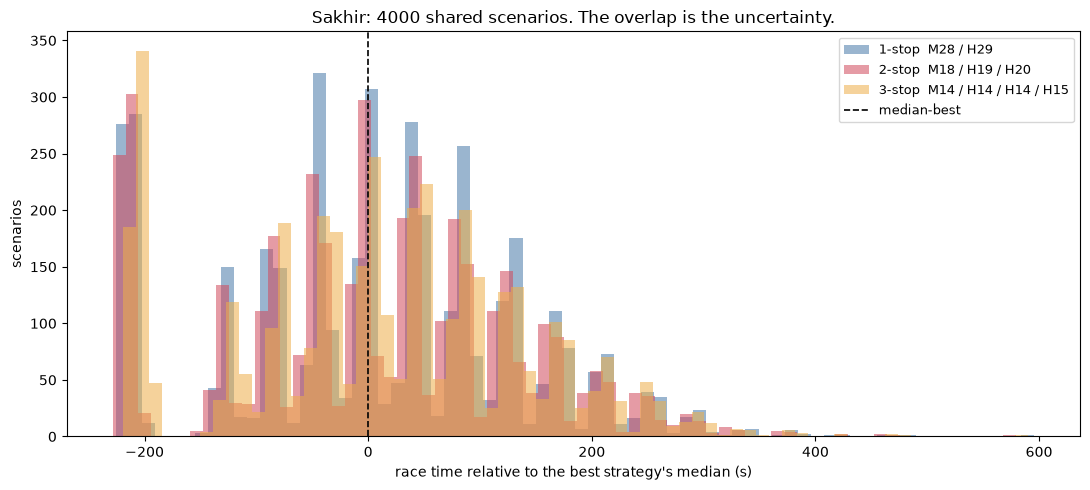

Wide, overlapping distributions -- but recall the MARGINS are tight.
The spread here is the shared safety-car penalty, not disagreement
between the strategies. This plot is honest and also misleading, which
is exactly why paired margins are the number to quote.


In [13]:
fig, ax = plt.subplots(figsize=(11,5))
colors = {1:'#4878a8', 2:'#d1495b', 3:'#edae49'}
for d in sorted(dists, key=lambda x: x.strategy.n_stops):
    rel = (d.total_ms - ref.median_ms)/1000
    ax.hist(rel, bins=70, alpha=0.55, label=f'{d.strategy.n_stops}-stop  {d.strategy.label()}',
            color=colors[d.strategy.n_stops])
ax.axvline(0, color='black', lw=1.2, ls='--', label='median-best')
ax.set_xlabel('race time relative to the best strategy\'s median (s)')
ax.set_ylabel('scenarios'); ax.legend(fontsize=9)
ax.set_title('Sakhir: 4000 shared scenarios. The overlap is the uncertainty.')
plt.tight_layout(); plt.show()
print('Wide, overlapping distributions -- but recall the MARGINS are tight.')
print('The spread here is the shared safety-car penalty, not disagreement')
print('between the strategies. This plot is honest and also misleading, which')
print('is exactly why paired margins are the number to quote.')

## 8. How much do the assumptions matter?

`SC_PIT_LOSS_FACTOR = 0.45` — how much cheaper a stop is under a safety car — is the least
defensible number in the model. It is an approximation, not a measurement.

The honest response is not to defend it but to vary it and see whether the conclusion survives.

In [14]:
sens = mc.sensitivity_to_sc_factor(strats, inp, factors=(0.25,0.45,0.65,1.0), n_scenarios=1500)
print(f'{'SC factor':>10}' + ''.join(f'{d.strategy.n_stops}-stop'.rjust(11) for d in dists))
for f, meds in sens.items():
    best = min(meds)
    print(f'{f:>10.2f}' + ''.join(f'{(m-best)/1000:>+10.1f}s' for m in meds))
print()
winners = {f: int(np.argmin(m)) for f, m in sens.items()}
print(f'winner at each factor: {set(winners.values())}')
print('Stable across the whole range -> the recommendation does NOT rest on that constant.')
print('Had it flipped, the right move would be to report the answer as uncertain.')

 SC factor     1-stop     2-stop     3-stop
      0.25      +2.5s      +0.0s     +11.1s
      0.45      +2.5s      +0.0s     +11.1s
      0.65      +2.5s      +0.0s     +11.2s
      1.00      +2.4s      +0.0s     +12.1s

winner at each factor: {1}
Stable across the whole range -> the recommendation does NOT rest on that constant.
Had it flipped, the right move would be to report the answer as uncertain.


---

## What Phase 3 established

| # | Finding |
|---|---|
| 1 | The entire trade-off is `slope * L*(L-1)/2 + stops * pit_loss` — three consequences follow for free |
| 2 | Stint **order** cannot affect the deterministic cost; only a safety car breaks that symmetry |
| 3 | A second stop pays above a **derivable threshold** (0.106 s/lap at 50 laps, 22s pit loss), and brute force agrees with the algebra |
| 4 | Pit loss must be `(in-lap + out-lap) − 2×pace`, not the pit-lane transit time |
| 5 | **The filter lesson, third time**: safety-car stops push p90 pit loss from 32s to 72s while barely moving the median |
| 6 | **Common random numbers** cut the comparison's noise 15× (sd 131s → 8.7s) from the same runs |
| 7 | A safety car changes the ranking through **one channel only** — pit timing. Its lap-time penalty cancels |
| 8 | More stops = more safety-car lottery tickets, which partly pays for them |
| 9 | The ranking survives `SC_PIT_LOSS_FACTOR` from 0.25 to 1.00 |
| 10 | Reproduces reality: Monza 1-stop, Sakhir 2-stop, Monaco 1-stop |

**The transferable lesson:** before simulating, look for the closed form. Here it took one line
of algebra and it gave three structural results, a derivable threshold, a 2.4-million-candidate
exhaustive search, and a test oracle for the simulator. Simulation is what you reach for when the
algebra runs out — not instead of trying it.

**And a decision-theory one:** ranking by expected value answers one question. "I am 15 seconds
behind" is a different question with a different answer, and the same simulation output answers
both.

## What this does NOT do

- **No competitors.** Single-car model, so no track position, traffic, undercut or overcut.
  Strategies are ranked by *race time*, not finishing position, and where overtaking is hard
  those differ. This is the biggest limitation and it would need a multi-car simulation.
- **Linear degradation.** Real tires can fall off a cliff; this under-penalises very long stints.
- **Dry races only.**

**Next:** `04_race_prediction.ipynb` — the hardest phase, and the one with the most ways to fool
yourself.